# Debugging and Sanity Checks
**Objective:** Build muscle memory for catching unit issues, NaNs, and shape mismatches before they contaminate downstream results.

## Structured Flow We'll Use
1. **Instrument logging early:** capture array stats with `utils.logging_helpers.get_logger`.
2. **Quick asserts:** shape, monotonic axes, and basic value ranges fail fast in seconds.
3. **`np.isfinite` masks:** quarantine NaNs/Infs before they poison summary statistics.
4. **Sanity plots:** eyeball raw, masked, and residual data separately to isolate pathologies.
5. **Interactive tools:** conditional breakpoints and `pdb` to ask _why_ a point is wrong.

In [ ]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from typing import Dict

# Ensure the repo root is importable even when this notebook is run from a nested folder
CWD = Path.cwd().resolve()
for candidate in (CWD, *CWD.parents):
    if candidate.exists():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from utils.logging_helpers import get_logger  # type: ignore

plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['axes.grid'] = True

logger = get_logger('class3.debugging')
logger.info('Notebook imports complete; matplotlib version %s', mpl.__version__)

2025-11-07 11:27:35 | INFO     | class3.debugging | Notebook imports complete; matplotlib version 3.10.7


## Synthetic spectrum with intentionally injected issues
We'll work with a tiny line spectrum containing:
- wavelength axis stored in microns but mislabeled as nm (1000× off),
- flux scaled up by 1e9 (pretend a mJy↔cgs conversion failed),
- sparse NaNs plus a contiguous missing chunk to stress masking/interpolation.

In [2]:
def generate_faulty_spectrum(n_points: int = 2048, seed: int = 7) -> Dict[str, np.ndarray]:
    """Return synthetic spectrum plus intentionally broken representations."""
    rng = np.random.default_rng(seed)
    wavelength_nm = np.linspace(500, 600, n_points)
    continuum = 4.2e-15
    amplitude = 6.8e-15
    width = 0.8
    line_profile = amplitude * np.exp(-0.5 * ((wavelength_nm - 557.0) / width) ** 2)
    noise = rng.normal(0.0, 1.5e-16, size=n_points)
    truth_flux = continuum + line_profile + noise

    reported_wavelength_nm = wavelength_nm / 1000  # BUG: storing microns but labeling nm
    reported_flux = truth_flux * 1e9               # BUG: forgot to down-convert units

    glitch_slice = slice(640, 700)
    reported_flux[glitch_slice] = np.nan

    reported_flux[5] = np.nan  # guarantee an early NaN for demos
    nan_indices = rng.choice(n_points, size=24, replace=False)
    reported_flux[nan_indices] = np.nan

    return {
        'reported_wavelength_nm': reported_wavelength_nm,
        'reported_flux': reported_flux,
        'truth_wavelength_nm': wavelength_nm,
        'truth_flux': truth_flux,
    }

In [3]:
record = generate_faulty_spectrum()
raw_wavelength = record['reported_wavelength_nm']
raw_flux = record['reported_flux']

summary = {
    'samples': raw_wavelength.size,
    'nan_count': int(np.count_nonzero(~np.isfinite(raw_flux))),
    'wavelength_span_nm_label': (float(raw_wavelength.min()), float(raw_wavelength.max())),
    'flux_range_reported': (float(np.nanmin(raw_flux)), float(np.nanmax(raw_flux)))
}
logger.info('Generated %d samples with %d NaNs', summary['samples'], summary['nan_count'])
summary

2025-11-07 11:27:35 | INFO     | class3.debugging | Generated 2048 samples with 84 NaNs


{'samples': 2048,
 'nan_count': 84,
 'wavelength_span_nm_label': (0.5, 0.6),
 'flux_range_reported': (3.7122842376755184e-06, 1.1072558159257996e-05)}

## Structured debugging checks
Layering fast diagnostics keeps us honest: quick asserts → monotonic/shape checks → finite-value masks → targeted logging about whatever failed.

In [4]:
def validate_inputs(wavelength: np.ndarray, flux: np.ndarray) -> np.ndarray:
    logger.info('Step 1: quick asserts + shape checks')
    assert wavelength.ndim == 1, 'Wavelength axis must be 1-D.'
    assert flux.shape == wavelength.shape, 'Flux must align with wavelength axis.'
    assert np.all(np.diff(wavelength) > 0), 'Wavelength values must be strictly increasing.'

    finite_mask = np.isfinite(flux)
    finite_fraction = finite_mask.mean()
    if finite_fraction < 1.0:
        logger.warning(
            'Flux contains %d non-finite samples (%.1f%%).',
            flux.size - finite_mask.sum(),
            (1.0 - finite_fraction) * 100
        )

    if wavelength.max() < 10:
        logger.error(
            'Wavelength max=%.3f nm looks suspicious—likely microns masquerading as nm.',
            float(wavelength.max())
        )
    max_flux = float(np.nanmax(flux))
    if max_flux > 1e-10:
        logger.error('Flux max=%.2e exceeds expected cgs levels; unit conversion probably missing.', max_flux)

    logger.info('Validation finished; %.1f%% of samples are finite.', finite_fraction * 100)
    return finite_mask

raw_finite_mask = validate_inputs(raw_wavelength, raw_flux)

2025-11-07 11:27:35 | INFO     | class3.debugging | Step 1: quick asserts + shape checks


2025-11-07 11:27:35 | WARNING  | class3.debugging | Flux contains 84 non-finite samples (4.1%).


2025-11-07 11:27:35 | ERROR    | class3.debugging | Wavelength max=0.600 nm looks suspicious—likely microns masquerading as nm.


2025-11-07 11:27:35 | ERROR    | class3.debugging | Flux max=1.11e-05 exceeds expected cgs levels; unit conversion probably missing.


2025-11-07 11:27:35 | INFO     | class3.debugging | Validation finished; 95.9% of samples are finite.


## Repair suspicious units, apply `np.isfinite` masks, and interpolate gaps

In [5]:
def fix_wavelength_units(wavelength_nm: np.ndarray) -> np.ndarray:
    if wavelength_nm.max() < 10:  # looks like microns
        logger.info('Converting reported microns back to nanometers (×1000).')
        return wavelength_nm * 1000
    return wavelength_nm


def fix_flux_units(flux: np.ndarray) -> np.ndarray:
    max_flux = float(np.nanmax(flux))
    if max_flux > 1e-10:
        logger.info('Scaling flux down by 1e9 to undo the unit inflation.')
        return flux * 1e-9
    return flux


def interpolate_nans(wavelength_nm: np.ndarray, flux: np.ndarray) -> np.ndarray:
    finite_mask = np.isfinite(flux)
    if finite_mask.all():
        return flux
    logger.info('Interpolating %d missing samples with np.interp.', np.count_nonzero(~finite_mask))
    filled = flux.copy()
    filled[~finite_mask] = np.interp(wavelength_nm[~finite_mask], wavelength_nm[finite_mask], flux[finite_mask])
    return filled

wavelength_nm = fix_wavelength_units(raw_wavelength)
flux_cgs = fix_flux_units(raw_flux)
finite_mask = np.isfinite(flux_cgs)
logger.info(
    'Finite mask retains %.1f%% (%d/%d) of the flux samples.',
    100 * finite_mask.mean(),
    int(finite_mask.sum()),
    finite_mask.size
)

masked_wavelength = wavelength_nm[finite_mask]
masked_flux = flux_cgs[finite_mask]
clean_flux = interpolate_nans(wavelength_nm, flux_cgs)

2025-11-07 11:27:35 | INFO     | class3.debugging | Converting reported microns back to nanometers (×1000).


2025-11-07 11:27:35 | INFO     | class3.debugging | Scaling flux down by 1e9 to undo the unit inflation.


2025-11-07 11:27:35 | INFO     | class3.debugging | Finite mask retains 95.9% (1964/2048) of the flux samples.


2025-11-07 11:27:35 | INFO     | class3.debugging | Interpolating 84 missing samples with np.interp.


## Conditional breakpoints in VS Code
- Open the **Run and Debug** panel (⇧⌘D or Ctrl+Shift+D) and launch the Python debugger on the script/notebook cell you care about.
- Click in the gutter next to the `if not np.isfinite(flux)` line inside `validate_inputs`, then right-click the red dot → **Edit Breakpoint…**.
- Add an expression such as `not np.isfinite(flux[idx]) and wavelength[idx] < 550` so VS Code only pauses on NaNs inside the blue wing.
- Use **Hit Count** (e.g., `>= 5`) to stop on the fifth violation or enable **Log message** to print diagnostics without halting execution.
- Inspect `flux[idx]`, `wavelength[idx]`, or run quick array slices directly inside the Debug Console before resuming.

In [6]:
import pdb

class AutoContinuePdb(pdb.Pdb):
    def interaction(self, frame, traceback):
        interesting = {k: frame.f_locals[k] for k in ('i', 'value', 'threshold') if k in frame.f_locals}
        logger.info('[pdb] Breakpoint at %s line %d | locals=%s', frame.f_code.co_name, frame.f_lineno, interesting)
        self.set_continue()

auto_pdb = AutoContinuePdb(skip=['pdb'])

def inspect_flux_segment(flux: np.ndarray, threshold: float = 1.1e-14) -> float:
    total = 0.0
    for i, value in enumerate(flux[:12]):
        if not np.isfinite(value):
            auto_pdb.set_trace()  # demo: would drop into pdb; here we auto-log + continue
        if value > threshold:
            total += value
    logger.info('Threshold %.2e accumulated %.2e across the first %d samples.', threshold, total, min(12, flux.size))
    return total

inspect_flux_segment(flux_cgs, threshold=1.1e-14)

2025-11-07 11:27:35 | INFO     | class3.debugging | [pdb] Breakpoint at inspect_flux_segment line 16 | locals={'i': 5, 'value': nan, 'threshold': 1.1e-14}


2025-11-07 11:27:35 | INFO     | class3.debugging | Threshold 1.10e-14 accumulated 0.00e+00 across the first 12 samples.


0.0

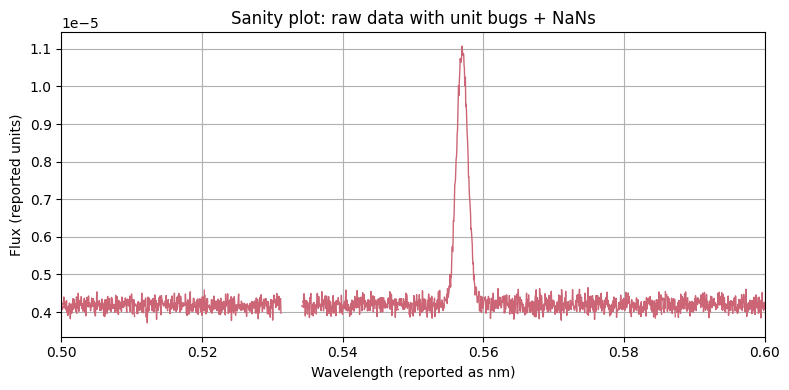

In [7]:
fig, ax = plt.subplots()
ax.plot(raw_wavelength, raw_flux, color='#CC6677', lw=1.0)
ax.set_xlabel('Wavelength (reported as nm)')
ax.set_ylabel('Flux (reported units)')
ax.set_title('Sanity plot: raw data with unit bugs + NaNs')
ax.margins(x=0)
fig.tight_layout()

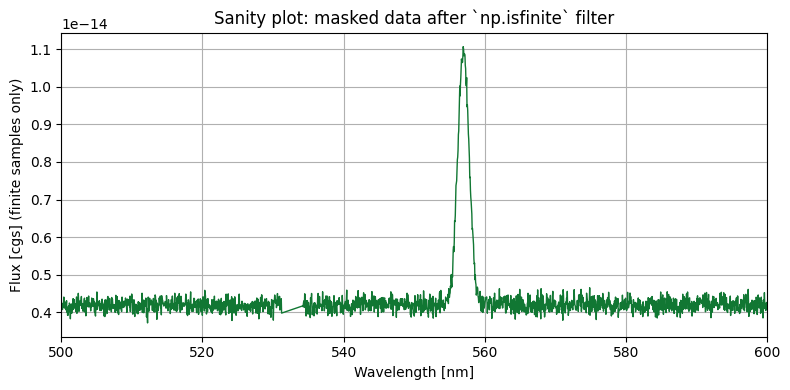

In [8]:
fig, ax = plt.subplots()
ax.plot(masked_wavelength, masked_flux, color='#117733', lw=1.0)
ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Flux [cgs] (finite samples only)')
ax.set_title('Sanity plot: masked data after `np.isfinite` filter')
ax.margins(x=0)
fig.tight_layout()

2025-11-07 11:27:35 | INFO     | class3.debugging | Residual RMS after fixes: 4.09e-17


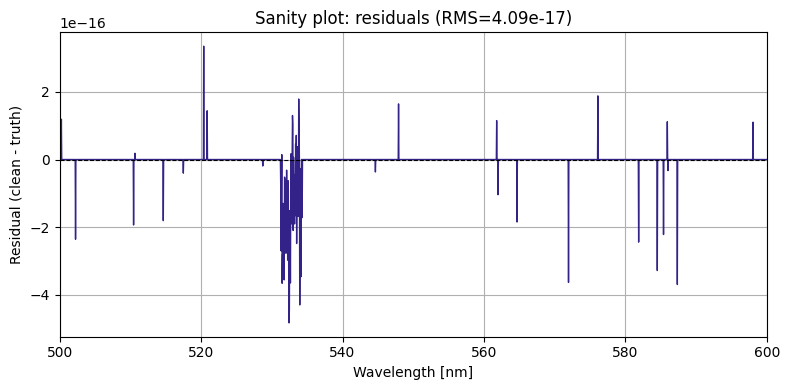

In [9]:
residual = clean_flux - record['truth_flux']
rms = float(np.sqrt(np.mean(residual ** 2)))
assert np.all(np.isfinite(residual)), 'Residual array still has non-finite values.'

fig, ax = plt.subplots()
ax.plot(wavelength_nm, residual, color='#332288', lw=1.0)
ax.axhline(0.0, color='black', lw=0.8, ls='--')
ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Residual (clean - truth)')
ax.set_title(f'Sanity plot: residuals (RMS={rms:.2e})')
ax.margins(x=0)
fig.tight_layout()

logger.info('Residual RMS after fixes: %.2e', rms)